<a href="https://colab.research.google.com/github/Amukta2906/Bioinformatics-/blob/main/sepsis_smote.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Handling Class Imbalance with SMOTE

**Project:** Finding the Gene Signal in Pediatric Septic Shock  
**Course:** BIOL 3340 – Bioinformatics, UT Arlington  
**Team:** Clarissa Bejar, Poorvaja Venkateswaran, Amukta Chaganty, Sidhantaa Sarna  
**Notebook author:** Sidhantaa Sarna  
**Dataset:** [GEO GSE66099](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE66099)

---

###Why this notebook exists
Our dataset is heavily imbalanced: **199 infected** children vs. **47 healthy** and **30 SIRS**.
A model can score ~72% accuracy just by calling everyone "infected," and our preliminary
models caught only **43% of SIRS** cases. This notebook tests **SMOTE** (Synthetic Minority
Oversampling Technique), which creates synthetic SIRS and healthy training samples by
interpolating between real ones, so the model sees a balanced training set.

This is one part of the team's imbalance analysis; class-weighted models are handled in a
separate notebook, and results are compared in the report.

###Models compared
| # | Model | Imbalance handling |
|---|---|---|
| 1 | Dummy (majority class) | none (chance-level floor) |
| 2 | Logistic regression | SMOTE |
| 3 | XGBoost | SMOTE |

###Leakage control
Probe selection, scaling, and SMOTE are all fit **inside each training fold**.
Every child is predicted exactly once, by a model that never saw them during training.

###How to run
Open in Google Colab → **Runtime → Run all**. The data downloads automatically from NCBI (~50 MB).

## 1. Setup
Install the packages Colab doesn't ship with and fix the random seed so results are reproducible.

In [ ]:
#GEOparse: reads GEO platform annotations (probe -> gene symbol)
#imbalanced-learn: SMOTE + a Pipeline that only resamples during training
!pip install -q GEOparse imbalanced-learn xgboost

import gzip
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")  # silence convergence / future warnings for readability

#One seed used everywhere (CV splits, SMOTE, XGBoost) -> rerunning gives identical numbers
SEED = 0
np.random.seed(SEED)

## 2. Download the data
We use the GEO **series matrix**, which holds both the normalized expression table and the
patient metadata (diagnosis labels). The raw `.CEL` files (1.3 GB) are not needed because
the submitters already gcRMA-normalized everything together.

> **If the download fails:** download `GSE66099_series_matrix.txt.gz` from the GEO page,
> drag it into Colab's file panel (folder icon on the left), rename it to `GSE66099.txt.gz`,
> and rerun this cell.

In [ ]:
FILENAME = "GSE66099.txt.gz"
URL = ("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE66nnn/GSE66099/"
       "matrix/GSE66099_series_matrix.txt.gz")

# Only download if the file isn't already there (saves time on reruns)
if not os.path.exists(FILENAME):
    !wget -q -O {FILENAME} {URL}

print(f"File size: {os.path.getsize(FILENAME) / 1e6:.1f} MB")

File size: 81.9 MB


## 3. Load the expression table and patient metadata
The series matrix mixes two things in one file:
- **Metadata lines** start with `!` (e.g., `!Sample_characteristics_ch1` holds `disease state: SIRS`)
- **The expression table**: rows = probes (~54,675), columns = patients (276)

In [ ]:
#Parse patient metadata
#Each '!Sample_characteristics_ch1' line has one 'key: value' entry per patient.
#A single line can mix keys across patients, so we parse every cell individually.
metadata, sample_ids = {}, None

with gzip.open(FILENAME, "rt") as f:
    for line in f:
        if line.startswith("!Sample_geo_accession"):
            # GSM IDs: the column order used everywhere else in the file
            sample_ids = [x.strip('"') for x in line.rstrip("\n").split("\t")[1:]]

        elif line.startswith("!Sample_characteristics_ch1"):
            for sample_id, cell in zip(sample_ids, line.rstrip("\n").split("\t")[1:]):
                cell = cell.strip('"')
                if ": " in cell:
                    key, value = cell.split(": ", 1)
                    metadata.setdefault(key.strip(), {})[sample_id] = value.strip()

metadata = pd.DataFrame(metadata)  # rows = patients, columns = clinical fields

#Load expression values
#comment="!" skips every metadata line, leaving only the numeric table
expression = pd.read_csv(FILENAME, sep="\t", comment="!", index_col=0)

print("Expression table (probes x patients):", expression.shape)   # expect (54675, 276)
print("Missing values:", int(expression.isna().sum().sum()))
print("Metadata fields:", metadata.columns.tolist())
metadata.head()

Expression table (probes x patients): (54675, 276)
Missing values: 0
Metadata fields: ['tissue', 'icu_day', 'disease']


,tissue,icu_day,disease
GSM1617492,whole blood,1,Control
GSM1617493,whole blood,1,Control
GSM1617494,whole blood,1,Control
GSM1617495,whole blood,1,Control
GSM1617496,whole blood,1,Control


## 4. Map probes to gene symbols
The Affymetrix HG-U133 Plus 2.0 array (platform **GPL570**) measures genes through probes.
Some genes have several probes, and some probes match several genes. We:
1. Drop probes that map to multiple genes (`///` in the annotation), since they're ambiguous
2. Average duplicate probes so each gene appears once

Note: the final models use probes (not collapsed genes) to match the team’s baseline; this mapping is kept for reference.

In [ ]:
import GEOparse

platform = GEOparse.get_GEO("GPL570", destdir="./data", silent=True)
annotation = platform.table[["ID", "Gene Symbol"]].dropna()

#Probes like 'GENE_A /// GENE_B' can't be attributed to one gene -> remove them
annotation = annotation[~annotation["Gene Symbol"].str.contains("///")]

#inner join keeps only annotated probes; groupby collapses duplicate probes per gene
gene_expression = (
    expression
    .join(annotation.set_index("ID"), how="inner")
    .groupby("Gene Symbol")
    .mean()
)

print("Gene table (genes x patients):", gene_expression.shape)

Gene table (genes x patients): (21655, 276)


## 5. Build the diagnosis labels
We group patients into 3 classes:
- **Healthy**: controls
- **SIRS**: non-infectious systemic inflammation
- **Infection**: sepsis + septic shock combined (sepsis alone is only ~12–18 patients, too few for its own class here)

Labels are matched by keyword so small spelling differences in GEO don't break the mapping.

**Check:** the counts should be **Infection 199, Healthy 47, SIRS 30**.

In [ ]:
#Find the metadata column that holds the diagnosis
#(usually 'disease state'; fall back to any column mentioning a diagnosis)
diagnosis_col = next((c for c in metadata.columns if "disease" in c.lower()), None)
if diagnosis_col is None:
    diagnosis_col = next(
        c for c in metadata.columns
        if metadata[c].str.contains("sirs|shock|sepsis|control", case=False).any()
    )

print("Diagnosis column:", diagnosis_col)
print(metadata[diagnosis_col].value_counts(), "\n")


def to_group(diagnosis):
    """Map a raw GEO diagnosis string to one of our 3 analysis classes."""
    d = str(diagnosis).lower()
    if "shock" in d or "sepsis" in d:
        return "Infection"
    if "sirs" in d:
        return "SIRS"
    if "control" in d or "normal" in d or "healthy" in d:
        return "Healthy"
    return np.nan  # anything unexpected gets flagged below


labels = metadata.loc[gene_expression.columns, diagnosis_col].map(to_group)

#Fail loudly instead of silently dropping patients
n_unlabeled = labels.isna().sum()
assert n_unlabeled == 0, f"{n_unlabeled} patients didn't match a class; update to_group()"

print(labels.value_counts())

Diagnosis column: disease
disease
SepticShock    181
Control         47
SIRS            30
Sepsis          18
Name: count, dtype: int64 

disease
Infection    199
Healthy       47
SIRS          30
Name: count, dtype: int64


### Final model inputs
- `X`: patients x genes matrix (scikit-learn expects samples as rows, so we transpose)
- `y`: integer class codes (XGBoost requires 0/1/2 rather than strings)

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
X = expression[gene_expression.columns].T.values.astype(np.float32)   #probes,to match teammate's baseline  # float32 halves memory, no accuracy cost
y = encoder.fit_transform(labels.values)
CLASSES = list(encoder.classes_)

print("X shape (patients x probes):", X.shape)
print("Class codes:", dict(enumerate(CLASSES)))

X shape (patients x probes): (276, 54675)
Class codes: {0: 'Healthy', 1: 'Infection', 2: 'SIRS'}


## 6. Define the models
Every model is a pipeline with the same steps:

**F-test top-500 genes → standardize → (SMOTE) → classifier**

Key design choices:
- **`imblearn.Pipeline`** applies SMOTE only when fitting, never when predicting, so test folds stay 100% real patients.
- **No class weights are used here.** SMOTE already balances the training data; adding class weights on top would correct the imbalance twice and over-predict small classes.
- **XGBoost is kept shallow** (`max_depth=3`) because with ~220 training patients and 500 genes, deep trees overfit.

In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

N_GENES = 500  #matches the team's 500-probe baseline

#Stratified: every fold keeps the same Healthy/SIRS/Infection proportions
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_pipeline(classifier, use_smote=False):
    """Probe selection -> scaling -> optional SMOTE -> classifier, all fit per training fold."""
    steps = [
        ("select", SelectKBest(f_classif, k=N_GENES)),  #top probes by ANOVA F-test
        ("scale", StandardScaler()),                    #SMOTE + LR need comparable probe scales
    ]
    if use_smote:
        #k_neighbors=5 is safe: each training fold has ~24 SIRS patients
        steps.append(("smote", SMOTE(k_neighbors=5, random_state=SEED)))
    steps.append(("clf", classifier))
    return Pipeline(steps)


def logistic_regression():
    #max_iter raised because high-dimensional data needs more iterations to converge
    return LogisticRegression(max_iter=5000)


def xgboost():
    return XGBClassifier(
        max_depth=3,           #shallow trees -> less overfitting on small data
        n_estimators=200,
        learning_rate=0.05,
        subsample=0.8,         #each tree sees 80% of patients
        colsample_bytree=0.5,  #each tree sees 50% of probes
        eval_metric="mlogloss",
        random_state=SEED,
        n_jobs=-1,
    )


#The dummy model is the floor: anything useful must beat it
models = {
    "Dummy (majority)": make_pipeline(DummyClassifier(strategy="most_frequent")),
    "LR + SMOTE":       make_pipeline(logistic_regression(), use_smote=True),
    "XGB + SMOTE":      make_pipeline(xgboost(), use_smote=True),
}

## 7. Run 5-fold cross-validation
We collect **pooled out-of-fold predictions**: each patient's prediction comes from the one fold
where they were in the test set. All metrics are then computed once over all 276 patients.

Metrics (chosen because plain accuracy is misleading with imbalanced classes):
- **Balanced accuracy**: average recall across the 3 classes
- **Macro-F1**: average F1 across classes, so small classes count equally
- **Macro AUC**: one-vs-rest ROC AUC averaged over classes
- **SIRS / Infection recall**: the two numbers in our success criteria

In [ ]:
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, recall_score, roc_auc_score,
)

SIRS_IDX = CLASSES.index("SIRS")
INF_IDX = CLASSES.index("Infection")

rows, predictions = [], {}

for name, pipeline in models.items():
    #Probabilities let us compute AUC; argmax turns them into class predictions
    proba = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba")
    pred = proba.argmax(axis=1)
    predictions[name] = pred

    per_class_recall = recall_score(y, pred, average=None)
    rows.append({
        "Model": name,
        "Balanced acc": balanced_accuracy_score(y, pred),
        "Macro-F1": f1_score(y, pred, average="macro"),
        "Macro AUC": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        "SIRS recall": per_class_recall[SIRS_IDX],
        "Infection recall": per_class_recall[INF_IDX],
    })
    print(f"Finished: {name}")

results = pd.DataFrame(rows).set_index("Model").round(3)
results

Finished: Dummy (majority)
Finished: LR + SMOTE
Finished: XGB + SMOTE


,Balanced acc,Macro-F1,Macro AUC,SIRS recall,Infection recall
Model,,,,,
Dummy (majority),0.333,0.279,0.500,0.000,1.000
LR + SMOTE,0.715,0.715,0.900,0.267,0.899
XGB + SMOTE,0.759,0.763,0.899,0.333,0.945


## 8. Check against our success criteria
From the proposal: **SIRS recall ≥ 0.50** (preliminary: 0.43) while keeping **infection recall ≥ 0.85**.
Both matter: raising SIRS recall is easy if the model starts mislabeling infected kids as SIRS.

In [ ]:
results["SIRS ≥ 0.50"] = results["SIRS recall"] >= 0.50
results["Infection ≥ 0.85"] = results["Infection recall"] >= 0.85
results

,Balanced acc,Macro-F1,Macro AUC,SIRS recall,Infection recall,SIRS ≥ 0.50,Infection ≥ 0.85
Model,,,,,,,
Dummy (majority),0.333,0.279,0.500,0.000,1.000,False,True
LR + SMOTE,0.715,0.715,0.900,0.267,0.899,False,True
XGB + SMOTE,0.759,0.763,0.899,0.333,0.945,False,True


## 9. Per-class performance
Precision, recall, and F1 for each class, per model (dummy skipped since it only predicts one class).

In [ ]:
from sklearn.metrics import classification_report

for name, pred in predictions.items():
    if name.startswith("Dummy"):
        continue
    print(f"===== {name} =====")
    print(classification_report(y, pred, target_names=CLASSES, digits=2))

===== LR + SMOTE =====
              precision    recall  f1-score   support

     Healthy       0.96      0.98      0.97        47
   Infection       0.89      0.90      0.90       199
        SIRS       0.30      0.27      0.28        30

    accuracy                           0.84       276
   macro avg       0.72      0.71      0.71       276
weighted avg       0.84      0.84      0.84       276

===== XGB + SMOTE =====
              precision    recall  f1-score   support

     Healthy       0.90      1.00      0.95        47
   Infection       0.92      0.94      0.93       199
        SIRS       0.53      0.33      0.41        30

    accuracy                           0.89       276
   macro avg       0.78      0.76      0.76       276
weighted avg       0.87      0.89      0.88       276



## 10. Confusion matrices
Rows = true class, columns = predicted class. The key cells to watch are **SIRS → Infection**
(missed SIRS cases) and **Infection → SIRS** (infected kids mislabeled).

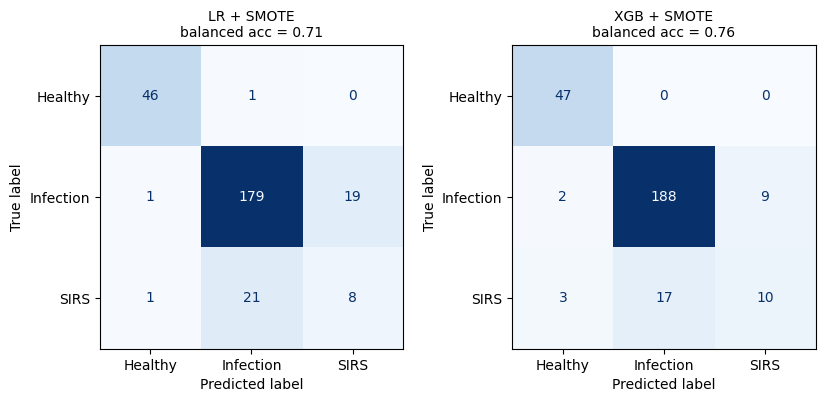

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

model_names = [n for n in predictions if not n.startswith("Dummy")]
fig, axes = plt.subplots(1, len(model_names), figsize=(4.2 * len(model_names), 4))

for ax, name in zip(axes, model_names):
    cm = confusion_matrix(y, predictions[name])
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nbalanced acc = {results.loc[name, 'Balanced acc']:.2f}", fontsize=10)

plt.tight_layout()
plt.savefig("smote_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. SIRS vs. infection recall trade-off
Dashed lines mark our success thresholds. A good model clears **both**.

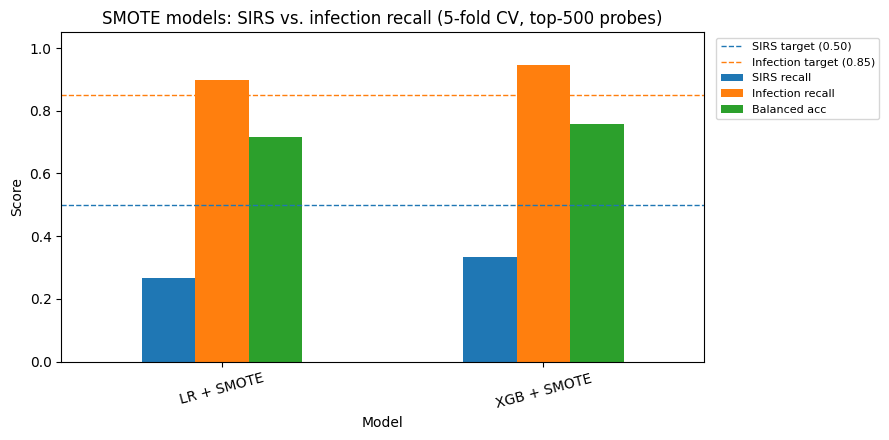

In [ ]:
plot_df = results.drop(index="Dummy (majority)")[["SIRS recall", "Infection recall", "Balanced acc"]]

ax = plot_df.plot.bar(figsize=(9, 4.5), rot=15)
ax.axhline(0.50, ls="--", lw=1, color="C0", label="SIRS target (0.50)")
ax.axhline(0.85, ls="--", lw=1, color="C1", label="Infection target (0.85)")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("SMOTE models: SIRS vs. infection recall (5-fold CV, top-500 probes)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.savefig("smote_recall_tradeoff.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Save outputs
These files go into the GitHub repo and the report.

In [ ]:
results.to_csv("smote_results.csv")
print(results.to_markdown())

#Saved: smote_results.csv, smote_confusion_matrices.png, smote_recall_tradeoff.png
#Download from Colab's file panel (folder icon, left sidebar)

| Model            |   Balanced acc |   Macro-F1 |   Macro AUC |   SIRS recall |   Infection recall | SIRS ≥ 0.50   | Infection ≥ 0.85   |
|:-----------------|---------------:|-----------:|------------:|--------------:|-------------------:|:--------------|:-------------------|
| Dummy (majority) |          0.333 |      0.279 |       0.5   |         0     |              1     | False         | True               |
| LR + SMOTE       |          0.715 |      0.715 |       0.9   |         0.267 |              0.899 | False         | True               |
| XGB + SMOTE      |          0.759 |      0.763 |       0.899 |         0.333 |              0.945 | False         | True               |


## Takeaways for the report
- **Leakage control:** probe selection (top 500 by F-test), scaling, and SMOTE were fit on training folds only. CV splits match the team's class-weighted baseline (5-fold stratified, `random_state=0`, top-500 probes).
- **Result:** SMOTE did not improve SIRS detection over class weighting.
  - LR + SMOTE: balanced accuracy 0.715, SIRS recall 0.27 (vs. 0.75 / 0.37 for LR + class weights)
  - XGB + SMOTE: balanced accuracy 0.759, SIRS recall 0.33, infection recall 0.95
  - Neither model met the SIRS recall target (≥ 0.50); both met the infection target (≥ 0.85).
- **Why:** synthetic samples are interpolated in 500-probe space from only ~24 real SIRS patients per fold, so they add little new information. Most SIRS patients (17–21 of 30) are still predicted as infection, suggesting real biological overlap rather than just small sample size.
- **Decision:** keep class weighting as the imbalance strategy; next, try threshold tuning and a two-stage model (healthy vs. ill, then SIRS vs. infection).

*AI assistance (Claude, Anthropic) was used to draft and comment this notebook; all code was run and results checked by the team. See `ai_usage.md` in the repo.*